# Real networks: repeated strategy comparison

Read-only analysis of the revised overnight experiment (`results/overnight_v2`). Run top to bottom after collection; this notebook never launches matching or training. Original results remain in `results/strategy_comparison`.

An independent random-seed pilot selects budgets per pair and matcher. Confirmation uses fresh random sets, five test partitions on small pairs and three on Wikipedia. Each partition holds out 20% of vertices from every selection rule. B relabelings and partitions measure robustness on the same native pair, not independent network realizations.

The seven core policies are random, exact top degree, clustered, spread, distinguishing, ER best-of-1,000, and ER best-found. Small pairs additionally include hub-free distinguishing and signature entropy. Rules use A only; ER weights remain the saved synthetic weights. Best-found uses four starts and sampled improving swaps, with its paired best-of-n as a starting candidate.


In [1]:
from pathlib import Path
import sys
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'experiment_common').is_dir())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import matplotlib.pyplot as plt
from IPython.display import display
from real_data_experiments import strategy_and_active_v2 as O, strategy_and_active_v2_analysis as N
from real_data_experiments import strategy_comparison as C
OUTPUT = O.OUTPUT_DIR
METRIC = 'accuracy_test'  # also 'accuracy_nonseed' or 'accuracy_all'
plt.rcParams.update({'font.size': 9, 'figure.dpi': 110})
O.status(OUTPUT)


Results: /Users/langsong/Desktop/Seeded-Graph-Matching/real_data_experiments/results/overnight_v2
Completed tasks: {'strategy': 4068, 'diagnostic': 94, 'active': 120, 'pilot': 36}
Unresolved errors: 0
{
  "state": "complete",
  "elapsed_hours": 5.571521602881945,
  "remaining_tasks": 0,
  "calibration_complete": true,
  "errors": 0,
  "updated_at": "2026-11-18T07:56:12-05:00"
}



## 1. Completion and evaluation metric

Each distinct seed set receives one percolation run or two FAQ/GOAT runs. The comparison includes a selection draw only after **all methods and solver repetitions** in its partition/budget/matcher are complete. Exact top degree is reused across draws; it is not multiple independently selected sets.

Means weight completed partitions equally after averaging selection draws within a partition. The shaded 10–90% ranges describe observed variability across solver-averaged draws and partitions. They are not confidence intervals over independent graphs. Inspect coverage before interpreting a partially finished run.

The default metric is fixed-test accuracy. Change `METRIC` above to examine all nonseeds or total accuracy including seeds; these answer different questions because queried vertices differ across policies.


At very small budgets, fewer than 1,000 distinct eligible seed sets may exist. Reference and screening pools then enumerate every possible set. Best-of-n draws can consequently coincide; this is expected, and their membership frequencies are retained.

In [2]:
data = N.read_strategy(OUTPUT)
summary = N.summarize_strategy(data, METRIC)
inventory = data['inventory']
if summary.empty:
    raise RuntimeError('No balanced strategy comparison is complete yet. Run or resume overnight collection.')
display(inventory.groupby('case').agg(partition_budget_matcher_blocks=('split', 'size'),
    complete_draws=('complete_draws', 'sum'), planned_draws=('planned_draws', 'sum'),
    solver_evaluations=('saved_evaluations', 'sum')))
print('Selected metric:', N.METRICS[METRIC])


,partition_budget_matcher_blocks,complete_draws,planned_draws,solver_evaluations
case,,,,
enron_100_101,45,360,360,3428
enron_100_102,45,360,360,3539
enron_130_131,45,360,360,3406
enron_130_132,45,360,360,4165
enron_145_146,45,360,360,3362
enron_145_147,45,360,360,4227
enron_160_161,45,360,360,3023
enron_160_162,45,360,360,3989
wikipedia,36,108,108,1008


Selected metric: Fixed-test accuracy


## 2. Accuracy versus seed budget

Budgets differ between matchers because their random-seed transitions differ. A pilot that stays uniformly low or high retains budgets across its tested range; this is not proof of an unavoidable floor or ceiling. Panel y-axes fit the displayed values, so compare their tick labels.

These randomized structural rules use the original degree-first candidate pool and choose among the top 20% of target-ranked candidates (at least two). Signature entropy considers all unused eligible vertices. ER scores are standardized against an independent fixed random pool within each partition/budget/matcher; best-of-n screening pools are fresh for each draw.


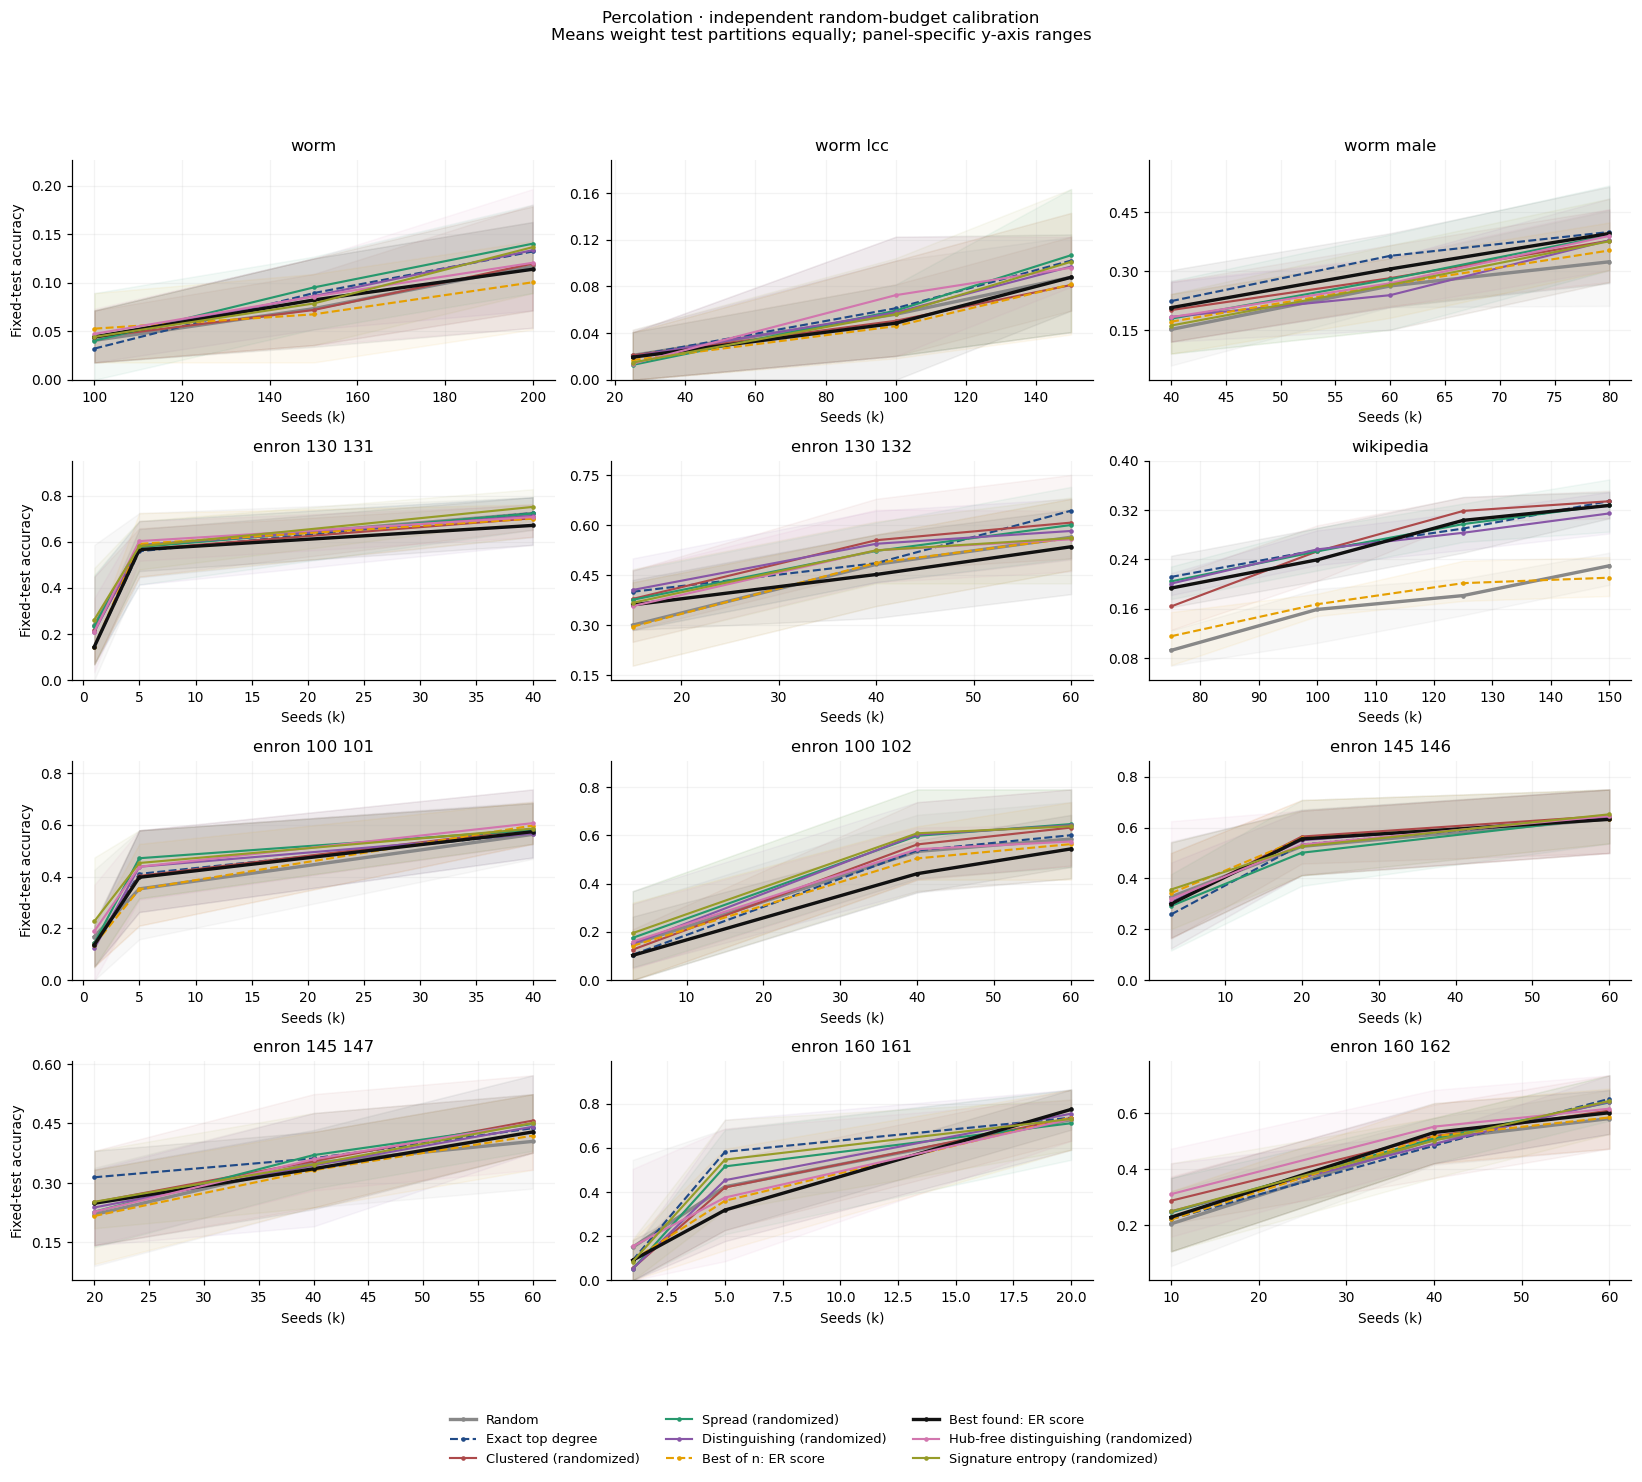

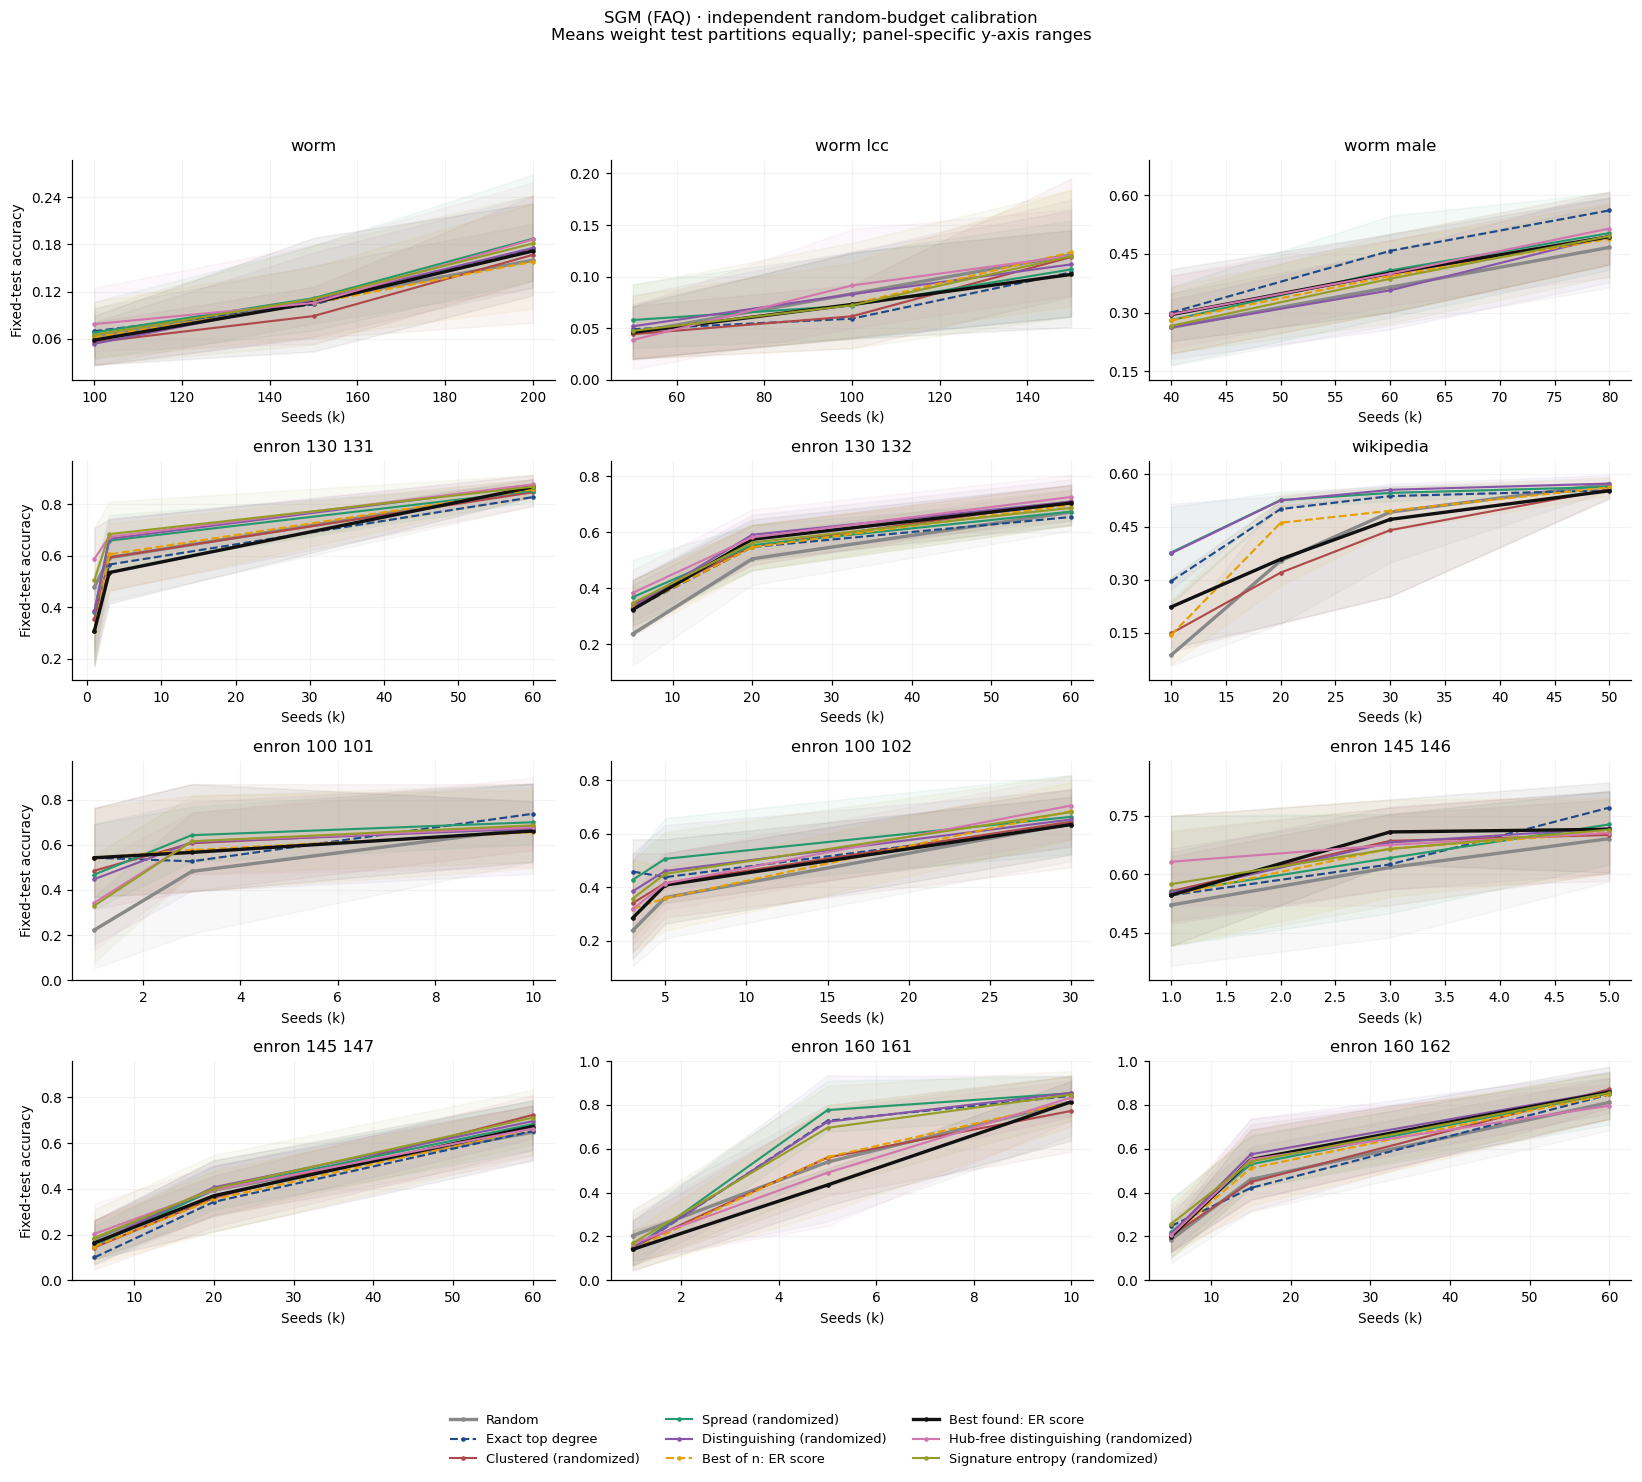

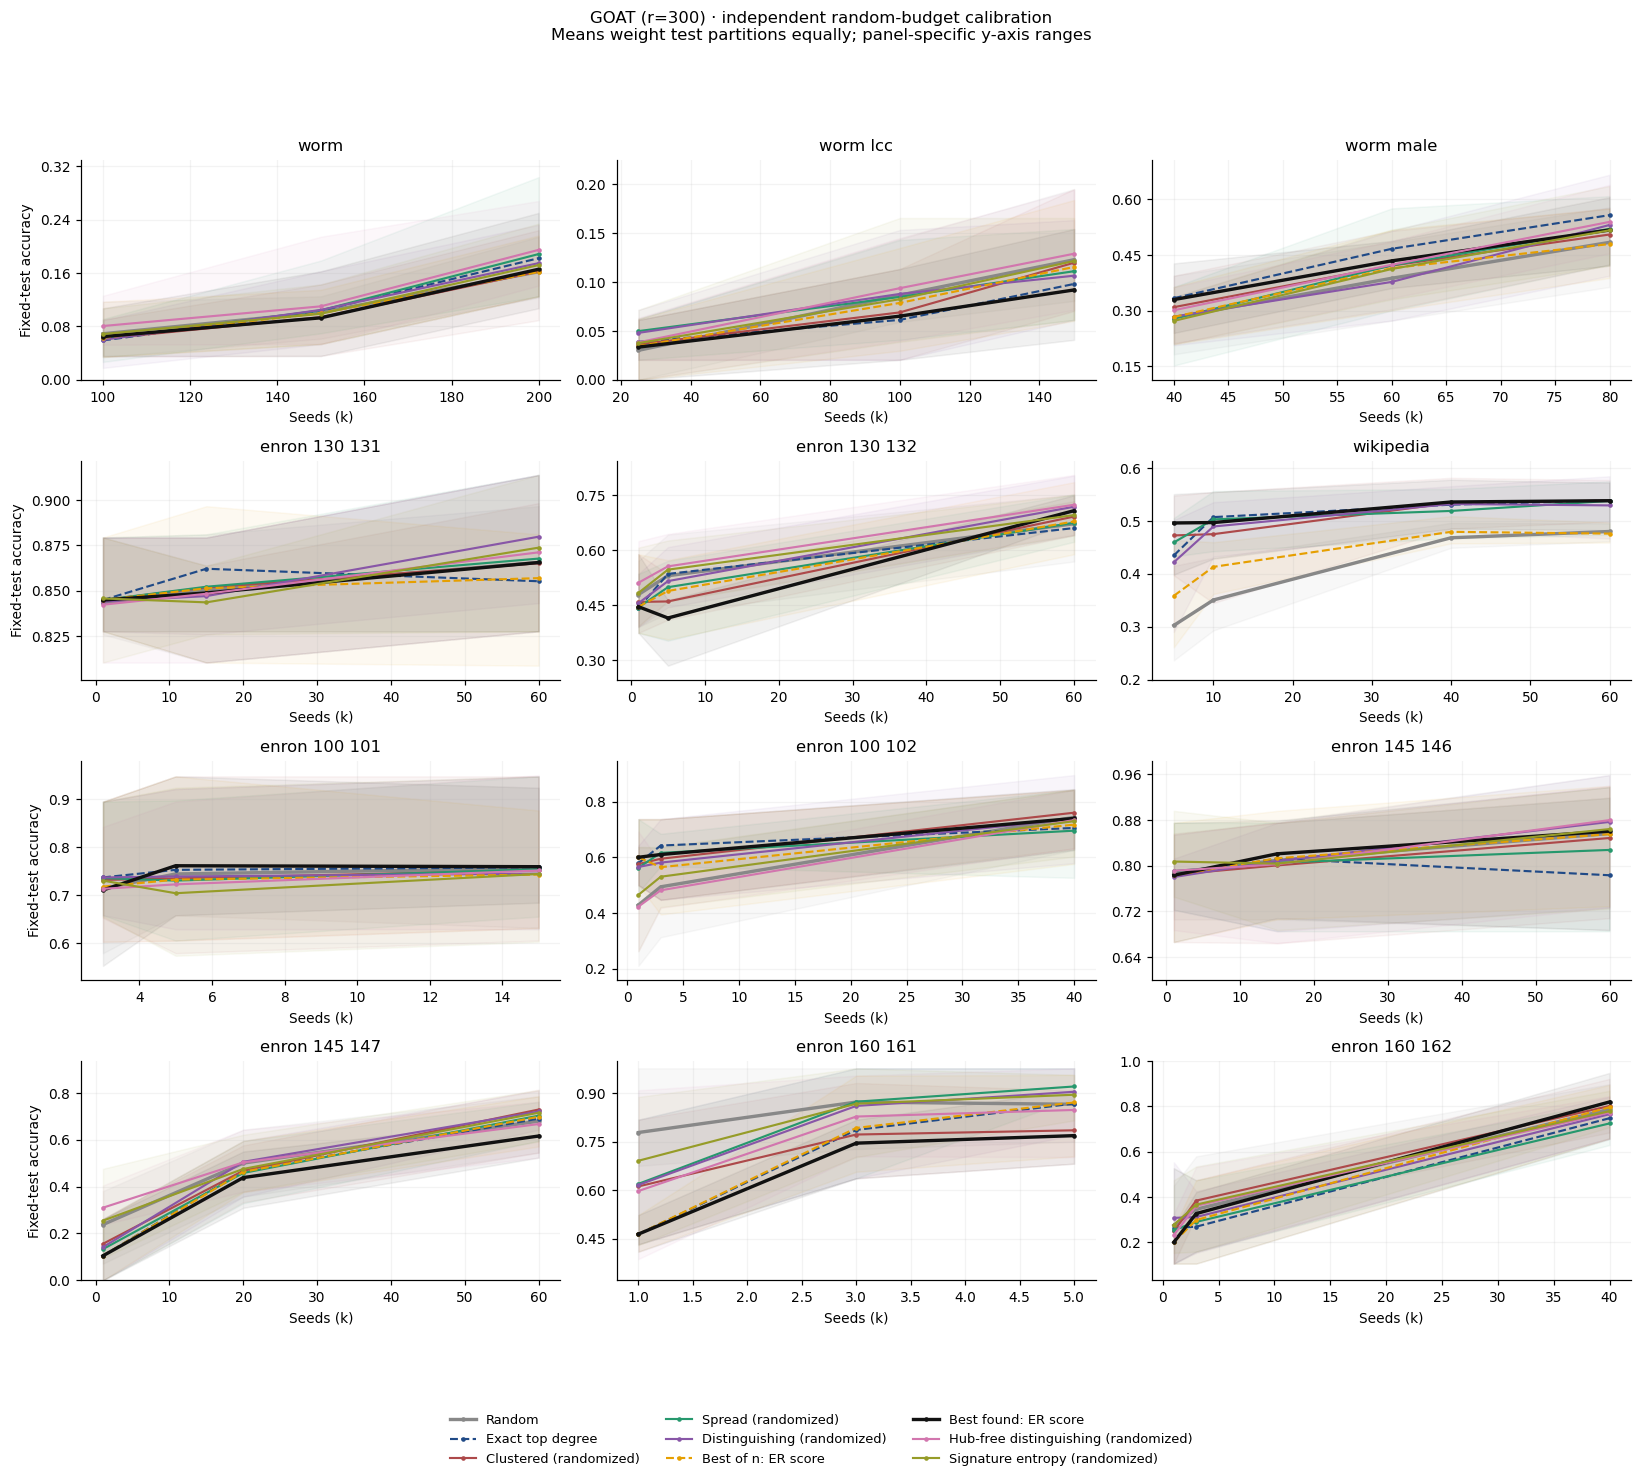

In [3]:
for algorithm in C.ALGORITHMS:
    if algorithm in set(summary.algorithm):
        fig = N.plot_strategy(summary, data, algorithm, OUTPUT, METRIC, bands=True)
        plt.show()
        plt.close(fig)


## 3. Gain over random

Gains pair methods with the random baseline on the same partition and draw, then weight partitions and completed budgets equally. These are results at independently calibrated budgets, not an estimate averaged over all possible budgets. Use the curves to see where a gain occurs; do not equate pilot accuracy above 0.65 with a structural ceiling.


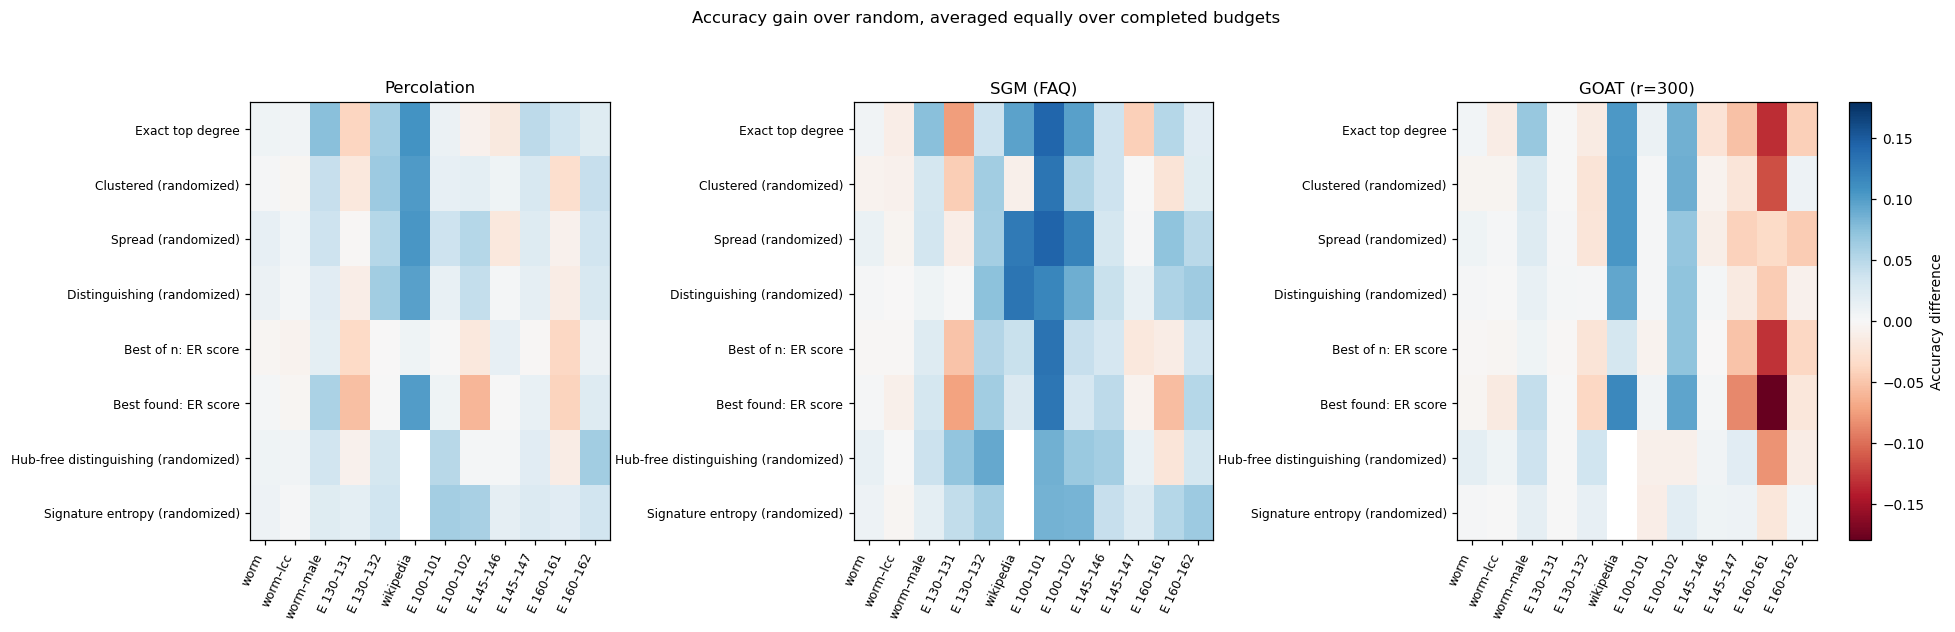

In [4]:
fig = C.plot_gains(summary, N.plot_config(data), OUTPUT)
plt.show()
plt.close(fig)


## 4. Seed-set overlap

This view compares selected sets within the same test partition, then averages partitions equally. Some overlap is unavoidable: independent uniform sets share a fraction k / eligible vertices on average. Distinct randomized draws may legitimately select identical sets; their selection frequency is retained.


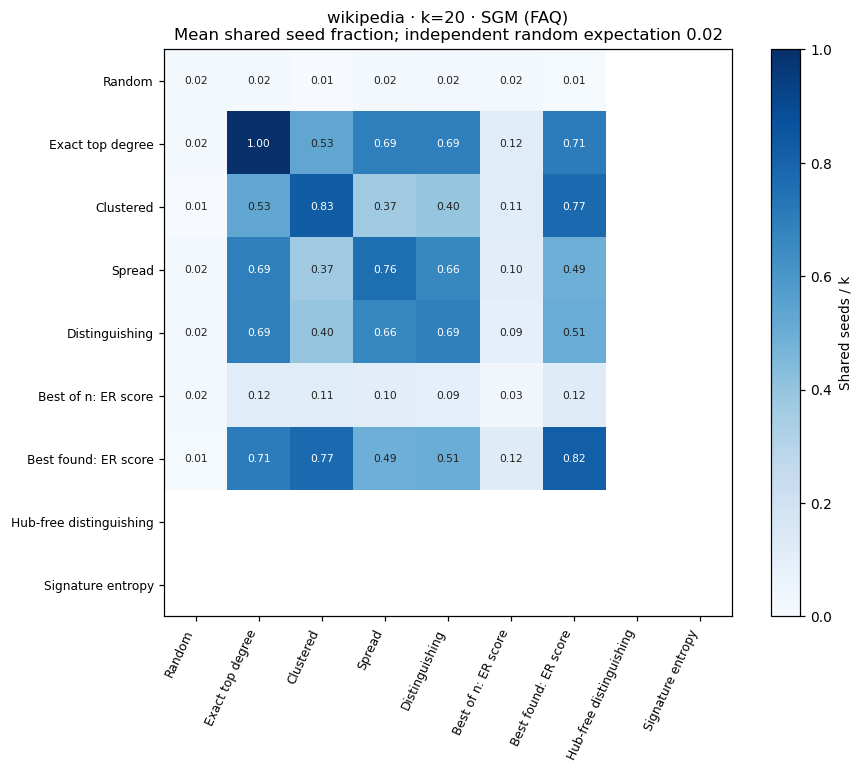

CSV summaries and figures: /Users/langsong/Desktop/Seeded-Graph-Matching/real_data_experiments/results/overnight_v2/analysis


In [5]:
overlap = N.overlaps(data, case='wikipedia', budget=20, algorithm='faq')
fig = C.plot_overlap(overlap, N.plot_config(data), case='wikipedia', budget=20,
                     algorithm='faq', root=OUTPUT)
plt.show()
plt.close(fig)
N.export(OUTPUT, strategy_inventory=inventory, strategy_draws=data['draws'],
         strategy_summary=summary, strategy_overlap=overlap)
print('CSV summaries and figures:', OUTPUT / 'analysis')


## Interpretation

Check whether gains recur across budgets and partitions, whether ER best-found improves on its paired screening baseline, and whether conclusions change between fixed-test and all-nonseed accuracy. Full worm and worm LCC are overlapping tasks, and Enron pairs share weeks; do not treat all cells as independent graph replications.

Raw `strategy/.../plan.json` files record selected nodes, memberships, score scales, and graph hashes. Each `c*_r*.npz` stores the assignment, per-vertex correctness, seeds, test indices, and scalar outcomes. Calibration outcomes are separate under `calibration/`. Neither notebook uses test outcomes to select seeds or train predictors.
